# 任务四：统一评估与不平衡处理

角色 C（邓闽川）负责统一评估；数据划分与预处理来自 A，NB、SVM、MLP 配置来自 B。若有 B 的原始预测，校验后直接用于留出集 ROC 和成绩单；若无，则按交付参数在同一划分上重训，不依赖发布逐条预测。五类模型同图，SVM 两种核分别画，因此有六条模型曲线，另列基线。

In [1]:
from IPython.display import Image, display
from task_four import B_OUTPUT_DIR, OUTPUT_DIR, run_evaluation

has_b_delivery = B_OUTPUT_DIR.is_dir()
print('B 模型留出集结果来源：' + ('交付预测（已校验）' if has_b_delivery else '按 B 的交付配置重训'))
scorecard, cv, comparison, changes, missing = run_evaluation(
    b_source=B_OUTPUT_DIR if has_b_delivery else None, refit_b=True
)
if missing:
    print('尚未接入：' + '、'.join(missing))

B 模型留出集结果来源：交付预测（已校验）


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (3 outputs left out)

/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 4.1 留出测试集 ROC

使用正类分数绘制 ROC，而不是硬分类标签。全不流失基线分数恒定，与对角参考线重合。

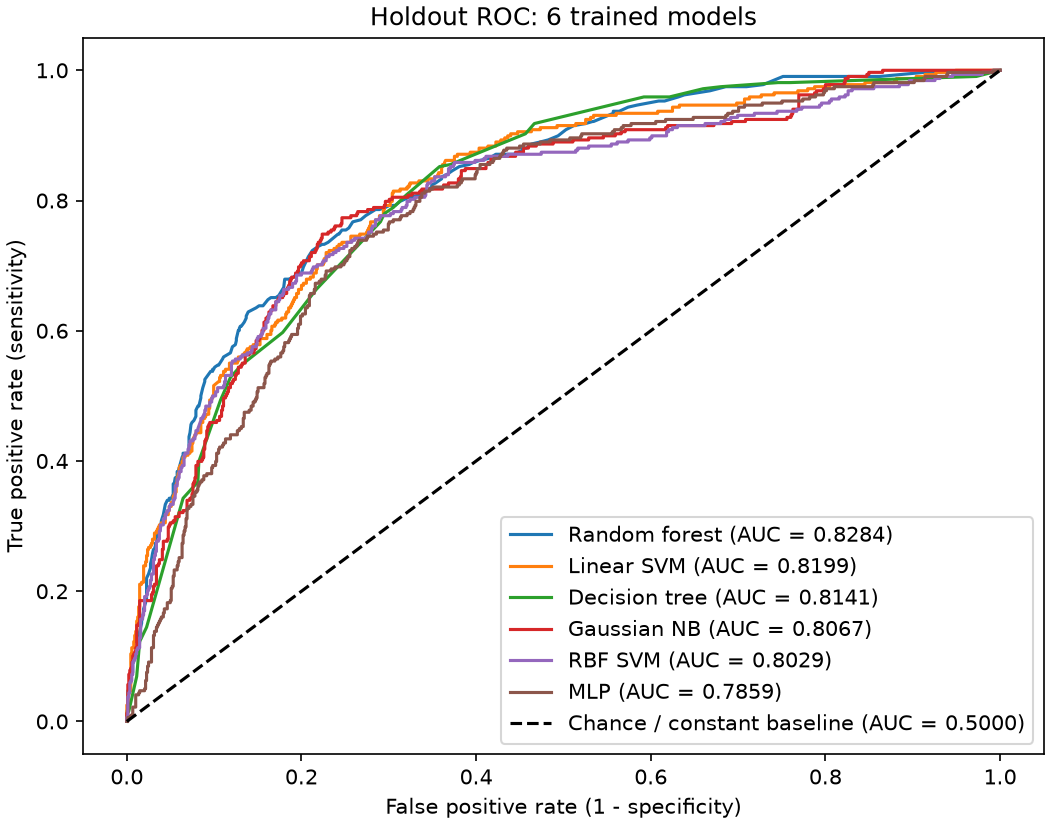

In [2]:
display(Image(filename=OUTPUT_DIR / 'fig07_roc_all.png'))

## 4.2 分层五折交叉验证

五折只在 A 的外层训练集上进行。复用 A 的已编码、未缩放矩阵；SVM 和 MLP 的缩放器在每折的 `Pipeline` 内拟合。决策树在每个外折的训练部分重新选深度，不先用全部训练集选深度再评分。这里验证的是 A 固定特征表示上的模型表现，不是从原始 CSV 按折重做清洗编码。

In [3]:
display(cv.round(4))
holdout_top = scorecard.iloc[0]['model']
cv_top = cv.iloc[0]['model']
print(f'当前对比：验证均值 AUC 最高的是 {cv_top}，留出集 AUC 最高的是 {holdout_top}。')

,model,fold_1,fold_2,fold_3,fold_4,fold_5,mean_auc,std_auc
3,SVM-线性核,0.8342,0.8463,0.8219,0.8363,0.8286,0.8334,0.0081
2,朴素贝叶斯,0.8134,0.8424,0.8215,0.8229,0.8138,0.8228,0.0105
1,随机森林,0.8024,0.8284,0.8153,0.8501,0.8070,0.8206,0.0172
0,决策树,0.8184,0.8367,0.7996,0.8306,0.8124,0.8195,0.0132
4,SVM-RBF核,0.7945,0.8271,0.7801,0.8179,0.7895,0.8018,0.0178
5,MLP,0.7335,0.7892,0.7463,0.7727,0.7698,0.7623,0.0198


当前对比：验证均值 AUC 最高的是 SVM-线性核，留出集 AUC 最高的是 随机森林。


## 4.3 默认与类别加权

随机森林和 RBF SVM 各自使用同一配置、数据和随机种子在本地成对重训，只改 `class_weight`。RBF SVM 的对照不跨环境使用 B 的原始默认结果。低成本触达可以考虑用更多误报换取更少漏报；人工挽留或发放优惠前，应结合触达成本和预计挽留收益。

,model,setting,acc,sens,spec,auc,tn,fp,fn,tp
0,随机森林,默认,0.8071,0.5377,0.9040,0.8284,800,85,147,171
1,随机森林,加权,0.7772,0.6635,0.8181,0.8288,724,161,107,211
2,SVM-RBF核,默认,0.7955,0.5000,0.9017,0.8029,798,87,159,159
3,SVM-RBF核,加权,0.7298,0.7484,0.7232,0.8060,640,245,80,238


,model,delta_sensitivity_pp,delta_specificity_pp,delta_tp,delta_fp
0,随机森林,12.58,-8.59,40,76
1,SVM-RBF核,24.84,-17.85,79,158


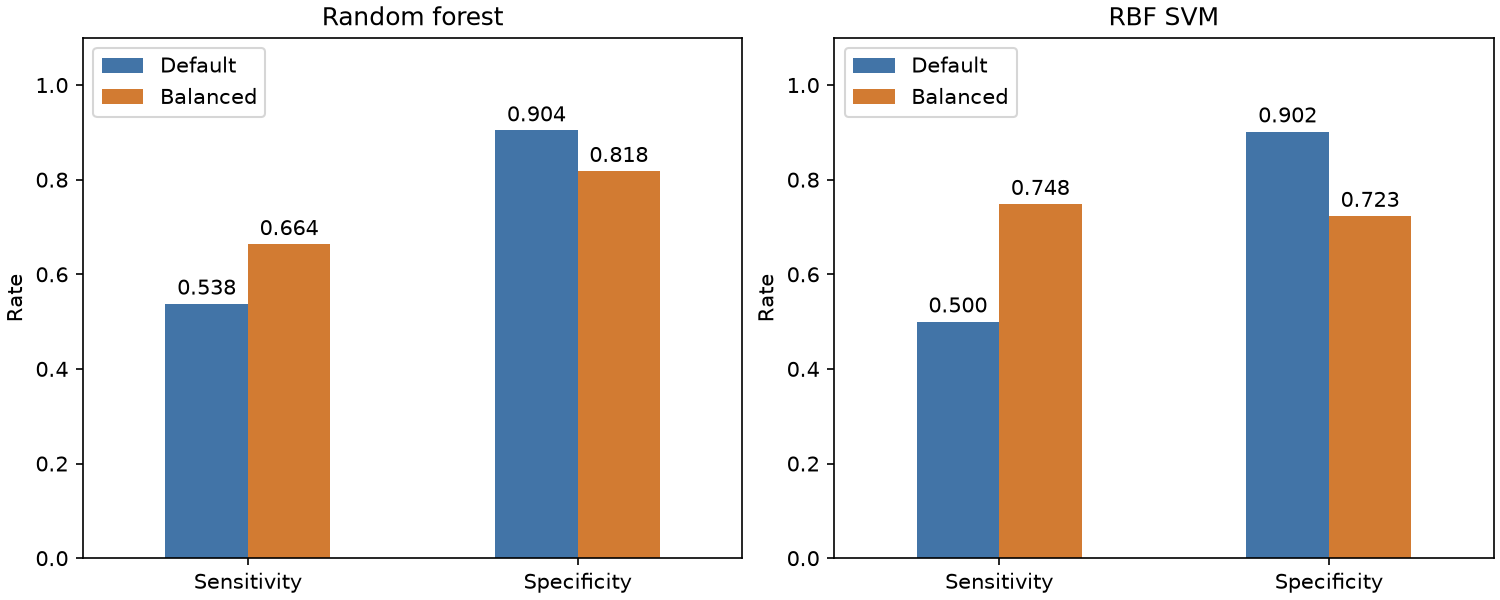

随机森林：加权后灵敏度 +12.58 个百分点，特异度 -8.59 个百分点；抓到的流失客户 +40 人，误报 +76 人。
SVM-RBF核：加权后灵敏度 +24.84 个百分点，特异度 -17.85 个百分点；抓到的流失客户 +79 人，误报 +158 人。


In [4]:
display(comparison.round(4), changes.round(2))
display(Image(filename=OUTPUT_DIR / 'fig08_imbalance.png'))
for row in changes.itertuples(index=False):
    print(f'{row.model}：加权后灵敏度 {row.delta_sensitivity_pp:+.2f} 个百分点，特异度 {row.delta_specificity_pp:+.2f} 个百分点；抓到的流失客户 {row.delta_tp:+d} 人，误报 {row.delta_fp:+d} 人。')

## 4.4 比武成绩单

按留出集 AUC 排序，不以准确率排名。实际选型还要根据可承受的误报规模和挽留成本检查灵敏度与特异度。

In [5]:
labels = {'model': '模型', 'acc': '准确率', 'sens': '灵敏度', 'spec': '特异度', 'auc': 'AUC'}
print(scorecard[list(labels)].rename(columns=labels).to_string(index=False, float_format='{:.4f}'.format))

      模型    准确率    灵敏度    特异度    AUC
    随机森林 0.8071 0.5377 0.9040 0.8284
 SVM-线性核 0.7938 0.5472 0.8825 0.8199
     决策树 0.7872 0.4937 0.8927 0.8141
   朴素贝叶斯 0.6492 0.8679 0.5706 0.8067
SVM-RBF核 0.7955 0.5000 0.9017 0.8029
     MLP 0.7598 0.5503 0.8350 0.7859
  全不流失基线 0.7357 0.0000 1.0000 0.5000
